In [1]:
import torch
import numpy as np
import pandas as pd
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import random
import os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from pathlib import Path
from sklearn.metrics import confusion_matrix, classification_report, roc_curve

from data_setup import TESSDataset, create_dataloaders
from torch.utils.data import DataLoader

In [ ]:
RANDOM_SEED = 42

def set_seed(seed: int = 42):
    # REPRODUCIBILITY
    
    random.seed(seed)
    
    os.environ['PYTHONHASHSEED'] = str(seed)
    
    np.random.seed(seed)
    
    torch.manual_seed(seed)
    
    if torch.backends.mps.is_available():
        torch.mps.manual_seed(seed)
        
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(42)

In [3]:
device = "mps" if torch.backends.mps.is_available() else "cpu"

if device == 'mps':
    torch.mps.manual_seed(RANDOM_SEED)

device

'mps'

In [4]:
csv_path = "data/processed_labels_v2.csv"
data_dir = "data/lightcurves_v2"
BATCH_SIZE = 32

In [5]:
def accuracy_fn(y_true, y_pred):
    y_pred_rounded = torch.round(y_pred)
    
    y_true_int = y_true.cpu().int()
    y_pred_int = y_pred_rounded.cpu().int()
    
    correct = torch.eq(y_true_int, y_pred_int).sum().item() 
    
    acc = (correct / len(y_pred)) * 100 
    return acc

In [6]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class TESSModelV5Aux(nn.Module):
    def __init__(self, n_aux_features = 1):
        super().__init__()
        
        self.aux_branch = nn.Sequential(
            nn.Linear(n_aux_features, 16),
            nn.ReLU(),
        )

        self.global_view = nn.Sequential(
            nn.Conv1d(
                in_channels = 1,
                out_channels = 16,
                kernel_size = 61,
                stride = 4,
                #padding = 30
            ),
            nn.BatchNorm1d(16),
            nn.LeakyReLU(0.1),
            nn.Dropout1d(p = 0.2),
            nn.MaxPool1d(kernel_size = 4),
            nn.Conv1d(
                in_channels = 16,
                out_channels = 32,
                kernel_size = 31,
                stride = 2,
                padding = 15
            ),
            nn.BatchNorm1d(32),
            nn.LeakyReLU(0.1),
            nn.Dropout1d(p = 0.2),
            nn.MaxPool1d(kernel_size = 4)
        )

        self.focused_view = nn.Sequential(
            nn.Conv1d(
                in_channels = 1,
                out_channels = 16,
                kernel_size = 5,
                stride = 2,
                #padding = 10
            ),
            nn.BatchNorm1d(16),
            nn.LeakyReLU(0.1),
            nn.Dropout1d(p = 0.2),
            nn.MaxPool1d(kernel_size = 2),
            nn.Conv1d(
                in_channels = 16,
                out_channels = 32,
                kernel_size = 5,
                stride = 1,
                #padding = 3
            ), 
            nn.BatchNorm1d(32),
            nn.LeakyReLU(0.1),
            nn.Dropout1d(p = 0.2),
            nn.MaxPool1d(kernel_size = 2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features = 128 + 16, out_features = 128),
            nn.BatchNorm1d(128),
            nn.LeakyReLU(0.1),
            nn.Dropout(p = 0.5), 
            nn.Linear(in_features = 128, out_features = 1)
        )

    def pool_branch(self, feat):
        avg = F.adaptive_avg_pool1d(feat, 1).squeeze(-1)
        mn = -F.adaptive_max_pool1d(-feat, 1).squeeze(-1)
        return torch.cat([avg, mn], dim = 1)
        
    def forward(self, x, aux):
        x_focused = x[:, :, 9000:11000]

        global_output = self.global_view(x)
        focused_output = self.focused_view(x_focused)

        global_summary  = self.pool_branch(global_output)
        focused_summary = self.pool_branch(focused_output)
        
        merge_views = torch.cat([global_summary, focused_summary], dim = 1)

        aux_out = self.aux_branch(aux)

        return self.classifier(torch.cat([merge_views, aux_out], dim = 1))

In [7]:
train_dataloader, test_dataloader = create_dataloaders(
    csv_path = csv_path,
    data_dir = data_dir,
    batch_size = BATCH_SIZE,
    aux_cols = ["log_period", "log_depth"]
)

print((~np.isfinite(train_dataloader.dataset.labels_df["log_period"])).sum())

Dataset initialized with 1784 strictly synced samples.
Dataset initialized with 447 strictly synced samples.
0


/Users/Vallabh/Desktop/ML/TESS_ML/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [8]:
import torch
import torch.optim as optim
import copy

results = []
per_seed_reports = []
summed_cm = np.zeros((2, 2), dtype=int)

probs_by_seed = {}
for seed in [1, 2, 3, 4, 5]:
    set_seed(seed)
    train_dataloader, test_dataloader = create_dataloaders(
        csv_path = csv_path,
        data_dir = data_dir,
        batch_size = BATCH_SIZE,
        aux_cols = ["log_period", "log_depth"],
        seed = seed
    )
    
    model_5aux = TESSModelV5Aux(n_aux_features = 2).to(device)
    
    loss_fn = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model_5aux.parameters(), lr = 0.001, weight_decay = 1e-4) ##
    
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, 
        mode = 'min', 
        factor = 0.5, 
        patience = 5
    )
    
    epochs = 100
    
    best_test_loss = float('inf')
    best_model_weights = None
    best_epoch = 0
    
    for epoch in range(epochs):
        ### TRAINING
        model_5aux.train() ##
        train_loss, train_accuracy = 0, 0
        
        for X, y, aux in train_dataloader:
            X, y, aux = X.to(device), y.to(device), aux.to(device)
    
            # Z-Score Normalization
            mean = X.mean(dim = 2, keepdim = True)
            std = X.std(dim = 2, keepdim = True)
            X = (X - mean) / (std + 1e-8)
            
            y = y.float().unsqueeze(dim = 1)
            
            y_pred = model_5aux(X, aux) ##
            
            loss = loss_fn(y_pred, y)
            train_loss += loss.item()
    
            y_pred_probs = torch.sigmoid(y_pred)
            train_accuracy += accuracy_fn(y_true = y, y_pred = y_pred_probs)
            
            optimizer.zero_grad()
            
            loss.backward()
            
            optimizer.step()
            
        train_loss /= len(train_dataloader)
        train_accuracy /= len(train_dataloader)
        
        ### TESTING
        model_5aux.eval() ##
        test_loss, test_accuracy = 0, 0
        
        with torch.inference_mode():
            for X_test, y_test, aux_test in test_dataloader:
                X_test, y_test, aux_test = X_test.to(device), y_test.to(device), aux_test.to(device)
    
                mean = X_test.mean(dim = 2, keepdim = True)
                std = X_test.std(dim = 2, keepdim = True)
                X_test = (X_test - mean) / (std + 1e-8)
    
                y_test = y_test.float().unsqueeze(dim = 1)
                
                test_pred = model_5aux(X_test, aux_test) ##
                
                loss = loss_fn(test_pred, y_test)
                test_loss += loss.item()
    
                test_pred_probs = torch.sigmoid(test_pred)
                test_accuracy += accuracy_fn(y_true = y_test, y_pred = test_pred_probs)
                
            test_loss /= len(test_dataloader)
            test_accuracy /= len(test_dataloader)
    
        scheduler.step(test_loss)
        current_lr = optimizer.param_groups[0]['lr']
            
        # Checkpointing implementation
        if test_loss < best_test_loss:
            best_test_loss = test_loss
            best_test_accuracy = test_accuracy
            best_epoch = epoch
            
            best_model_weights = copy.deepcopy(model_5aux.state_dict()) ##
            checkpoint_msg = "|Saved|"
            
        else:
            checkpoint_msg = ""
            
        # Print
        if checkpoint_msg:
            print(f"Epoch {epoch} | LR: {current_lr:.8f} | Train Loss: {train_loss:.4f} Accuracy: {train_accuracy:.2f}% | Test Loss: {test_loss:.4f} Accuracy: {test_accuracy:.2f}% {checkpoint_msg}")
    
    # Load the captured best state of the model
    print(f"Best state captured at Epoch: {best_epoch}, test loss: {best_test_loss:.4f}, test accuracy: {best_test_accuracy:.2f}")
    
    # Overwrite model with captured best state
    model_5aux.load_state_dict(best_model_weights) ##

    torch.save(best_model_weights, f"model_seed_{seed}.pt")
    
    results.append({
        "seed": seed,
        "test_acc": best_test_accuracy,
        "test_loss": best_test_loss,
    })

    model_5aux.eval()
    all_true, all_probs = [], []
    with torch.inference_mode():
        for X_test, y_test, aux_test in test_dataloader:
            X_test, aux_test = X_test.to(device), aux_test.to(device)
            mean = X_test.mean(dim=2, keepdim=True); std = X_test.std(dim=2, keepdim=True)
            X_test = (X_test - mean) / (std + 1e-8)
            probs = torch.sigmoid(model_5aux(X_test, aux_test)).squeeze().cpu().numpy()
            all_probs.extend(np.atleast_1d(probs))
            all_true.extend(np.atleast_1d(y_test.squeeze().cpu().numpy()))

    all_true, all_probs = np.array(all_true), np.array(all_probs)
    probs_by_seed[seed] = all_probs.copy()
    fpr, tpr, thresholds = roc_curve(all_true, all_probs)
    opt_threshold = thresholds[np.argmax(tpr - fpr)]
    all_preds = (all_probs >= opt_threshold).astype(int)

    report = classification_report(all_true, all_preds, target_names=['No Planet (0)', 'Planet (1)'], output_dict=True)
    report["seed"] = seed
    per_seed_reports.append(report)
    summed_cm += confusion_matrix(all_true, all_preds)

print(np.allclose(probs_by_seed[1], probs_by_seed[2]))
print(np.max(np.abs(probs_by_seed[1] - probs_by_seed[2])))

results_df = pd.DataFrame(results)
print(results_df)
print(f"Mean accuracy: {results_df['test_acc'].mean():.3f} ± {results_df['test_acc'].std():.3f}")


/Users/Vallabh/Desktop/ML/TESS_ML/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


Dataset initialized with 1784 strictly synced samples.
Dataset initialized with 447 strictly synced samples.
Epoch 0 | LR: 0.00100000 | Train Loss: 0.6984 Accuracy: 54.87% | Test Loss: 0.6665 Accuracy: 64.65% |Saved|
Epoch 1 | LR: 0.00100000 | Train Loss: 0.6864 Accuracy: 57.53% | Test Loss: 0.6462 Accuracy: 64.18% |Saved|
Epoch 3 | LR: 0.00100000 | Train Loss: 0.6646 Accuracy: 60.75% | Test Loss: 0.6392 Accuracy: 63.30% |Saved|
Epoch 4 | LR: 0.00100000 | Train Loss: 0.6662 Accuracy: 60.90% | Test Loss: 0.6288 Accuracy: 66.43% |Saved|
Epoch 6 | LR: 0.00100000 | Train Loss: 0.6573 Accuracy: 62.37% | Test Loss: 0.6229 Accuracy: 67.99% |Saved|
Epoch 10 | LR: 0.00100000 | Train Loss: 0.6507 Accuracy: 64.36% | Test Loss: 0.6136 Accuracy: 68.66% |Saved|
Epoch 11 | LR: 0.00100000 | Train Loss: 0.6369 Accuracy: 65.72% | Test Loss: 0.6069 Accuracy: 68.89% |Saved|
Epoch 17 | LR: 0.00100000 | Train Loss: 0.6440 Accuracy: 63.34% | Test Loss: 0.6039 Accuracy: 70.23% |Saved|
Epoch 19 | LR: 0.0010000

/Users/Vallabh/Desktop/ML/TESS_ML/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


Dataset initialized with 1784 strictly synced samples.
Dataset initialized with 447 strictly synced samples.
Epoch 0 | LR: 0.00100000 | Train Loss: 0.6951 Accuracy: 54.63% | Test Loss: 0.6385 Accuracy: 64.87% |Saved|
Epoch 1 | LR: 0.00100000 | Train Loss: 0.6758 Accuracy: 60.08% | Test Loss: 0.6319 Accuracy: 65.76% |Saved|
Epoch 2 | LR: 0.00100000 | Train Loss: 0.6712 Accuracy: 60.96% | Test Loss: 0.6256 Accuracy: 66.88% |Saved|
Epoch 3 | LR: 0.00100000 | Train Loss: 0.6659 Accuracy: 60.86% | Test Loss: 0.6237 Accuracy: 67.32% |Saved|
Epoch 4 | LR: 0.00100000 | Train Loss: 0.6594 Accuracy: 62.22% | Test Loss: 0.6181 Accuracy: 67.77% |Saved|
Epoch 6 | LR: 0.00100000 | Train Loss: 0.6496 Accuracy: 63.23% | Test Loss: 0.6138 Accuracy: 68.44% |Saved|
Epoch 8 | LR: 0.00100000 | Train Loss: 0.6478 Accuracy: 63.73% | Test Loss: 0.6072 Accuracy: 68.44% |Saved|
Epoch 10 | LR: 0.00100000 | Train Loss: 0.6473 Accuracy: 64.84% | Test Loss: 0.6064 Accuracy: 69.11% |Saved|
Epoch 14 | LR: 0.00100000 

/Users/Vallabh/Desktop/ML/TESS_ML/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


Dataset initialized with 1784 strictly synced samples.
Dataset initialized with 447 strictly synced samples.
Epoch 0 | LR: 0.00100000 | Train Loss: 0.7144 Accuracy: 51.82% | Test Loss: 0.6375 Accuracy: 67.32% |Saved|
Epoch 1 | LR: 0.00100000 | Train Loss: 0.6830 Accuracy: 58.63% | Test Loss: 0.6257 Accuracy: 67.09% |Saved|
Epoch 2 | LR: 0.00100000 | Train Loss: 0.6672 Accuracy: 61.14% | Test Loss: 0.6245 Accuracy: 67.99% |Saved|
Epoch 3 | LR: 0.00100000 | Train Loss: 0.6611 Accuracy: 61.40% | Test Loss: 0.6201 Accuracy: 66.42% |Saved|
Epoch 4 | LR: 0.00100000 | Train Loss: 0.6640 Accuracy: 61.50% | Test Loss: 0.6155 Accuracy: 67.55% |Saved|
Epoch 6 | LR: 0.00100000 | Train Loss: 0.6485 Accuracy: 63.54% | Test Loss: 0.6073 Accuracy: 68.44% |Saved|
Epoch 14 | LR: 0.00050000 | Train Loss: 0.6366 Accuracy: 64.75% | Test Loss: 0.6045 Accuracy: 69.78% |Saved|
Epoch 15 | LR: 0.00050000 | Train Loss: 0.6360 Accuracy: 66.22% | Test Loss: 0.6021 Accuracy: 69.78% |Saved|
Epoch 17 | LR: 0.00050000

/Users/Vallabh/Desktop/ML/TESS_ML/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


Dataset initialized with 1784 strictly synced samples.
Dataset initialized with 447 strictly synced samples.
Epoch 0 | LR: 0.00100000 | Train Loss: 0.7065 Accuracy: 55.51% | Test Loss: 0.6425 Accuracy: 65.32% |Saved|
Epoch 1 | LR: 0.00100000 | Train Loss: 0.6693 Accuracy: 60.99% | Test Loss: 0.6260 Accuracy: 65.76% |Saved|
Epoch 4 | LR: 0.00100000 | Train Loss: 0.6587 Accuracy: 61.40% | Test Loss: 0.6249 Accuracy: 68.89% |Saved|
Epoch 6 | LR: 0.00100000 | Train Loss: 0.6564 Accuracy: 62.15% | Test Loss: 0.6199 Accuracy: 67.55% |Saved|
Epoch 8 | LR: 0.00100000 | Train Loss: 0.6484 Accuracy: 63.65% | Test Loss: 0.6069 Accuracy: 68.89% |Saved|
Epoch 13 | LR: 0.00100000 | Train Loss: 0.6382 Accuracy: 64.17% | Test Loss: 0.6067 Accuracy: 69.78% |Saved|
Epoch 14 | LR: 0.00100000 | Train Loss: 0.6462 Accuracy: 63.58% | Test Loss: 0.6018 Accuracy: 69.11% |Saved|
Epoch 15 | LR: 0.00100000 | Train Loss: 0.6425 Accuracy: 66.16% | Test Loss: 0.5999 Accuracy: 70.23% |Saved|
Epoch 17 | LR: 0.0010000

/Users/Vallabh/Desktop/ML/TESS_ML/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


Dataset initialized with 1784 strictly synced samples.
Dataset initialized with 447 strictly synced samples.
Epoch 0 | LR: 0.00100000 | Train Loss: 0.7145 Accuracy: 51.49% | Test Loss: 0.6560 Accuracy: 65.78% |Saved|
Epoch 1 | LR: 0.00100000 | Train Loss: 0.6906 Accuracy: 57.11% | Test Loss: 0.6451 Accuracy: 62.63% |Saved|
Epoch 2 | LR: 0.00100000 | Train Loss: 0.6692 Accuracy: 61.01% | Test Loss: 0.6350 Accuracy: 66.43% |Saved|
Epoch 3 | LR: 0.00100000 | Train Loss: 0.6686 Accuracy: 60.97% | Test Loss: 0.6336 Accuracy: 66.65% |Saved|
Epoch 4 | LR: 0.00100000 | Train Loss: 0.6630 Accuracy: 60.90% | Test Loss: 0.6259 Accuracy: 66.88% |Saved|
Epoch 6 | LR: 0.00100000 | Train Loss: 0.6542 Accuracy: 62.48% | Test Loss: 0.6243 Accuracy: 66.65% |Saved|
Epoch 7 | LR: 0.00100000 | Train Loss: 0.6480 Accuracy: 62.87% | Test Loss: 0.6151 Accuracy: 68.22% |Saved|
Epoch 8 | LR: 0.00100000 | Train Loss: 0.6543 Accuracy: 63.82% | Test Loss: 0.6139 Accuracy: 67.77% |Saved|
Epoch 9 | LR: 0.00100000 | 

Optimal threshold: 0.481
               precision    recall  f1-score   support

No Planet (0)       0.77      0.56      0.65       215
   Planet (1)       0.67      0.84      0.75       232

     accuracy                           0.71       447
    macro avg       0.72      0.70      0.70       447
 weighted avg       0.72      0.71      0.70       447



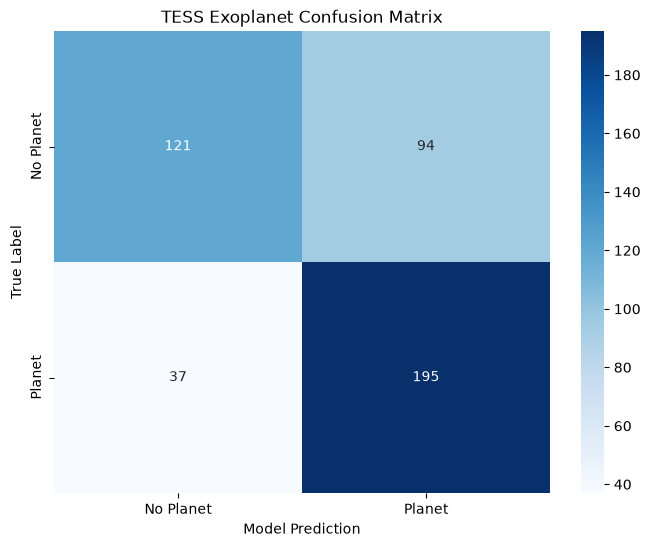

In [9]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

model_5aux = TESSModelV5Aux(n_aux_features=2).to(device)
model_5aux.load_state_dict(torch.load("model_seed_3.pt"))
model_5aux.eval() ##

all_preds = []
all_true = []
all_probs = []
all_raw_flux = []

with torch.inference_mode():
    for X_test, y_test, aux_test in test_dataloader:
        X_test, aux_test = X_test.to(device), aux_test.to(device)

        all_raw_flux.append(X_test.cpu())

        mean = X_test.mean(dim = 2, keepdim = True)
        std = X_test.std(dim = 2, keepdim = True)
        X_test = (X_test - mean) / (std + 1e-8)
        
        test_logits = model_5aux(X_test, aux_test) ##
        test_probs = torch.sigmoid(test_logits).squeeze().cpu().numpy() 

        if test_probs.ndim == 0:
            all_probs.append(test_probs)
        else:
            all_probs.extend(test_probs)
        
        all_true.extend(y_test.squeeze().cpu().numpy())

all_true = np.array(all_true)
all_probs = np.array(all_probs)
X_test_raw = torch.cat(all_raw_flux)


fpr, tpr, thresholds = roc_curve(all_true, all_probs)
youden_j = tpr - fpr
best_idx = np.argmax(youden_j)
opt_threshold = thresholds[best_idx]
print(f"Optimal threshold: {opt_threshold:.3f}")

all_preds = (all_probs >= opt_threshold).astype(int)

print(classification_report(all_true, all_preds, target_names = ['No Planet (0)', 'Planet (1)']))

cm = confusion_matrix(all_true, all_preds)

plt.figure(figsize = (8, 6))
sns.heatmap(cm, annot = True, fmt = 'd', cmap = 'Blues', 
            xticklabels = ['No Planet', 'Planet'],
            yticklabels = ['No Planet', 'Planet'])

plt.title("TESS Exoplanet Confusion Matrix")
plt.ylabel("True Label")
plt.xlabel("Model Prediction")
plt.show()

In [10]:
for r in per_seed_reports:
    print(r["seed"], r["accuracy"])

1 0.7114093959731543
2 0.7069351230425056
3 0.7069351230425056
4 0.7114093959731543
5 0.70917225950783


In [11]:
print([id(r) for r in per_seed_reports])

[5029303488, 5029584512, 5029270144, 5029453568, 4769237952]


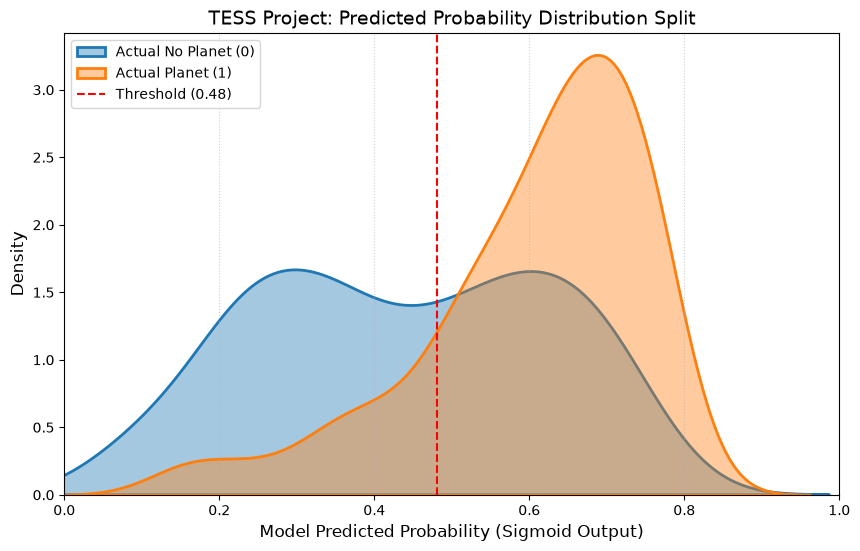

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

probs_arr = np.array(all_probs)
true_arr = np.array(all_true)

plt.figure(figsize=(10, 6))

sns.kdeplot(
    probs_arr[true_arr == 0], 
    label = 'Actual No Planet (0)', 
    fill = True, 
    alpha = 0.4,
    linewidth = 2
)

sns.kdeplot(
    probs_arr[true_arr == 1], 
    label = 'Actual Planet (1)', 
    fill = True, 
    alpha = 0.4,
    linewidth = 2
)

plt.axvline(x = opt_threshold, color = 'red', linestyle = '--', label = f'Threshold ({opt_threshold:.2f})')

plt.title('TESS Project: Predicted Probability Distribution Split', fontsize = 14)
plt.xlabel('Model Predicted Probability (Sigmoid Output)', fontsize = 12)
plt.ylabel('Density', fontsize = 12)
plt.xlim(0, 1)
plt.legend(loc = 'upper left')
plt.grid(axis = 'x', linestyle = ':', alpha = 0.6)
plt.show()

In [ ]:
# DEPTH SHORTCUT CHECK 1
depths = 1.0 - X_test_raw.amin(dim=2).squeeze().cpu().numpy() 
shallow_mask = (true_arr == 1) & (depths < 0.01)
deep_mask    = (true_arr == 1) & (depths >= 0.03)

print("Shallow planets - mean predicted prob:", probs_arr[shallow_mask].mean())
print("Deep planets — mean predicted prob:", probs_arr[deep_mask].mean())

Shallow planets — mean predicted prob: 0.54108596
Deep planets — mean predicted prob: 0.6784102


In [ ]:
# DEPTH SHORTCUT CHECK 2
shallow_np_mask = (true_arr == 0) & (depths < 0.01)
deep_np_mask    = (true_arr == 0) & (depths >= 0.03)

print("Shallow No-Planet — mean predicted prob:", probs_arr[shallow_np_mask].mean())
print("Deep No-Planet — mean predicted prob:", probs_arr[deep_np_mask].mean())

Shallow No-Planet — mean predicted prob: 0.40138653
Deep No-Planet — mean predicted prob: 0.50347596


In [11]:
for seed in [1, 2, 3, 4, 5]:
    model_5aux = TESSModelV5Aux(n_aux_features=2).to(device)
    model_5aux.load_state_dict(torch.load(f"model_seed_{seed}.pt"))
    model_5aux.eval()

    all_true = []
    all_probs = []
    all_raw_flux = []

    with torch.inference_mode():
        for X_test, y_test, aux_test in test_dataloader:
            X_test, aux_test = X_test.to(device), aux_test.to(device)
            all_raw_flux.append(X_test.cpu())

            mean = X_test.mean(dim=2, keepdim=True)
            std = X_test.std(dim=2, keepdim=True)
            X_test = (X_test - mean) / (std + 1e-8)

            test_logits = model_5aux(X_test, aux_test)
            test_probs = torch.sigmoid(test_logits).squeeze().cpu().numpy()
            all_probs.extend(np.atleast_1d(test_probs))
            all_true.extend(np.atleast_1d(y_test.squeeze().cpu().numpy()))

    all_true = np.array(all_true)
    all_probs = np.array(all_probs)
    X_test_raw = torch.cat(all_raw_flux)

    depths = 1.0 - X_test_raw.amin(dim=2).squeeze().cpu().numpy()
    shallow_mask = (all_true == 1) & (depths < 0.01)
    deep_mask    = (all_true == 1) & (depths >= 0.03)
    shallow_np_mask = (all_true == 0) & (depths < 0.01)
    deep_np_mask    = (all_true == 0) & (depths >= 0.03)

    planet_gap = all_probs[deep_mask].mean() - all_probs[shallow_mask].mean()
    no_planet_gap = all_probs[deep_np_mask].mean() - all_probs[shallow_np_mask].mean()

    print(f"Seed {seed}: Planet gap = {planet_gap:.4f}, No-Planet gap = {no_planet_gap:.4f}")

Seed 1: Planet gap = 0.1382, No-Planet gap = 0.0891
Seed 2: Planet gap = 0.1441, No-Planet gap = 0.1010
Seed 3: Planet gap = 0.1373, No-Planet gap = 0.1021
Seed 4: Planet gap = 0.1409, No-Planet gap = 0.1043
Seed 5: Planet gap = 0.1340, No-Planet gap = 0.1202


In [14]:
diag_dataset = TESSDataset(
    labels_df = test_dataloader.dataset.labels_df,
    lightcurves_dir = data_dir,
    transform = None,
    aux_cols = ["log_period", "log_depth"],
    aux_stats = test_dataloader.dataset.aux_stats,
    return_id = True
)
diag_loader = DataLoader(diag_dataset, batch_size = 32, shuffle = False)

model_5aux.eval()
records = []
with torch.inference_mode():
    for X, y, aux, tic_id in diag_loader:
        X, aux = X.to(device), aux.to(device)
        mean = X.mean(dim=2, keepdim=True); std = X.std(dim=2, keepdim=True)
        X = (X - mean) / (std + 1e-8)
        probs = torch.sigmoid(model_5aux(X, aux)).squeeze().cpu().numpy()
        probs = np.atleast_1d(probs)
        for i in range(len(tic_id)):
            records.append({
                "tic_id": int(tic_id[i]),
                "true_label": int(y[i].item()),
                "pred_prob": float(probs[i]),
            })

diag_df = pd.DataFrame(records)
no_planet = diag_df[diag_df["true_label"] == 0].copy()
no_planet["dist_from_threshold"] = (no_planet["pred_prob"] - 0.5).abs()
no_planet = no_planet.sort_values("dist_from_threshold")

print(no_planet.head(30)[["tic_id", "pred_prob"]])

Dataset initialized with 454 strictly synced samples.


/Users/Vallabh/Desktop/ML/TESS_ML/data_setup.py:105: RuntimeWarning: invalid value encountered in scalar subtract
  v = (v - mean) / (std + 1e-8)


        tic_id  pred_prob
103   32283946   0.500589
48   243153196   0.499106
125  304021498   0.497627
282   90544017   0.496116
277  219380235   0.504446
426  366563452   0.495269
29   300013921   0.505821
268  382188882   0.493733
116  164150539   0.506498
94   341815767   0.492882
440  157528286   0.492335
57   160268701   0.491693
427  255918903   0.509388
299  286696848   0.511342
317  416539317   0.488398
267  305943739   0.487329
73    96097215   0.512928
133  341444900   0.513459
425  108645766   0.513698
54   294780517   0.514192
196  271900960   0.514403
394  389182138   0.514466
305  131419878   0.484923
272  122485078   0.515392
122  430528566   0.515782
130  431899140   0.481523
453  364408162   0.481455
263  289539327   0.518594
248  259863352   0.480820
179  305550963   0.520688


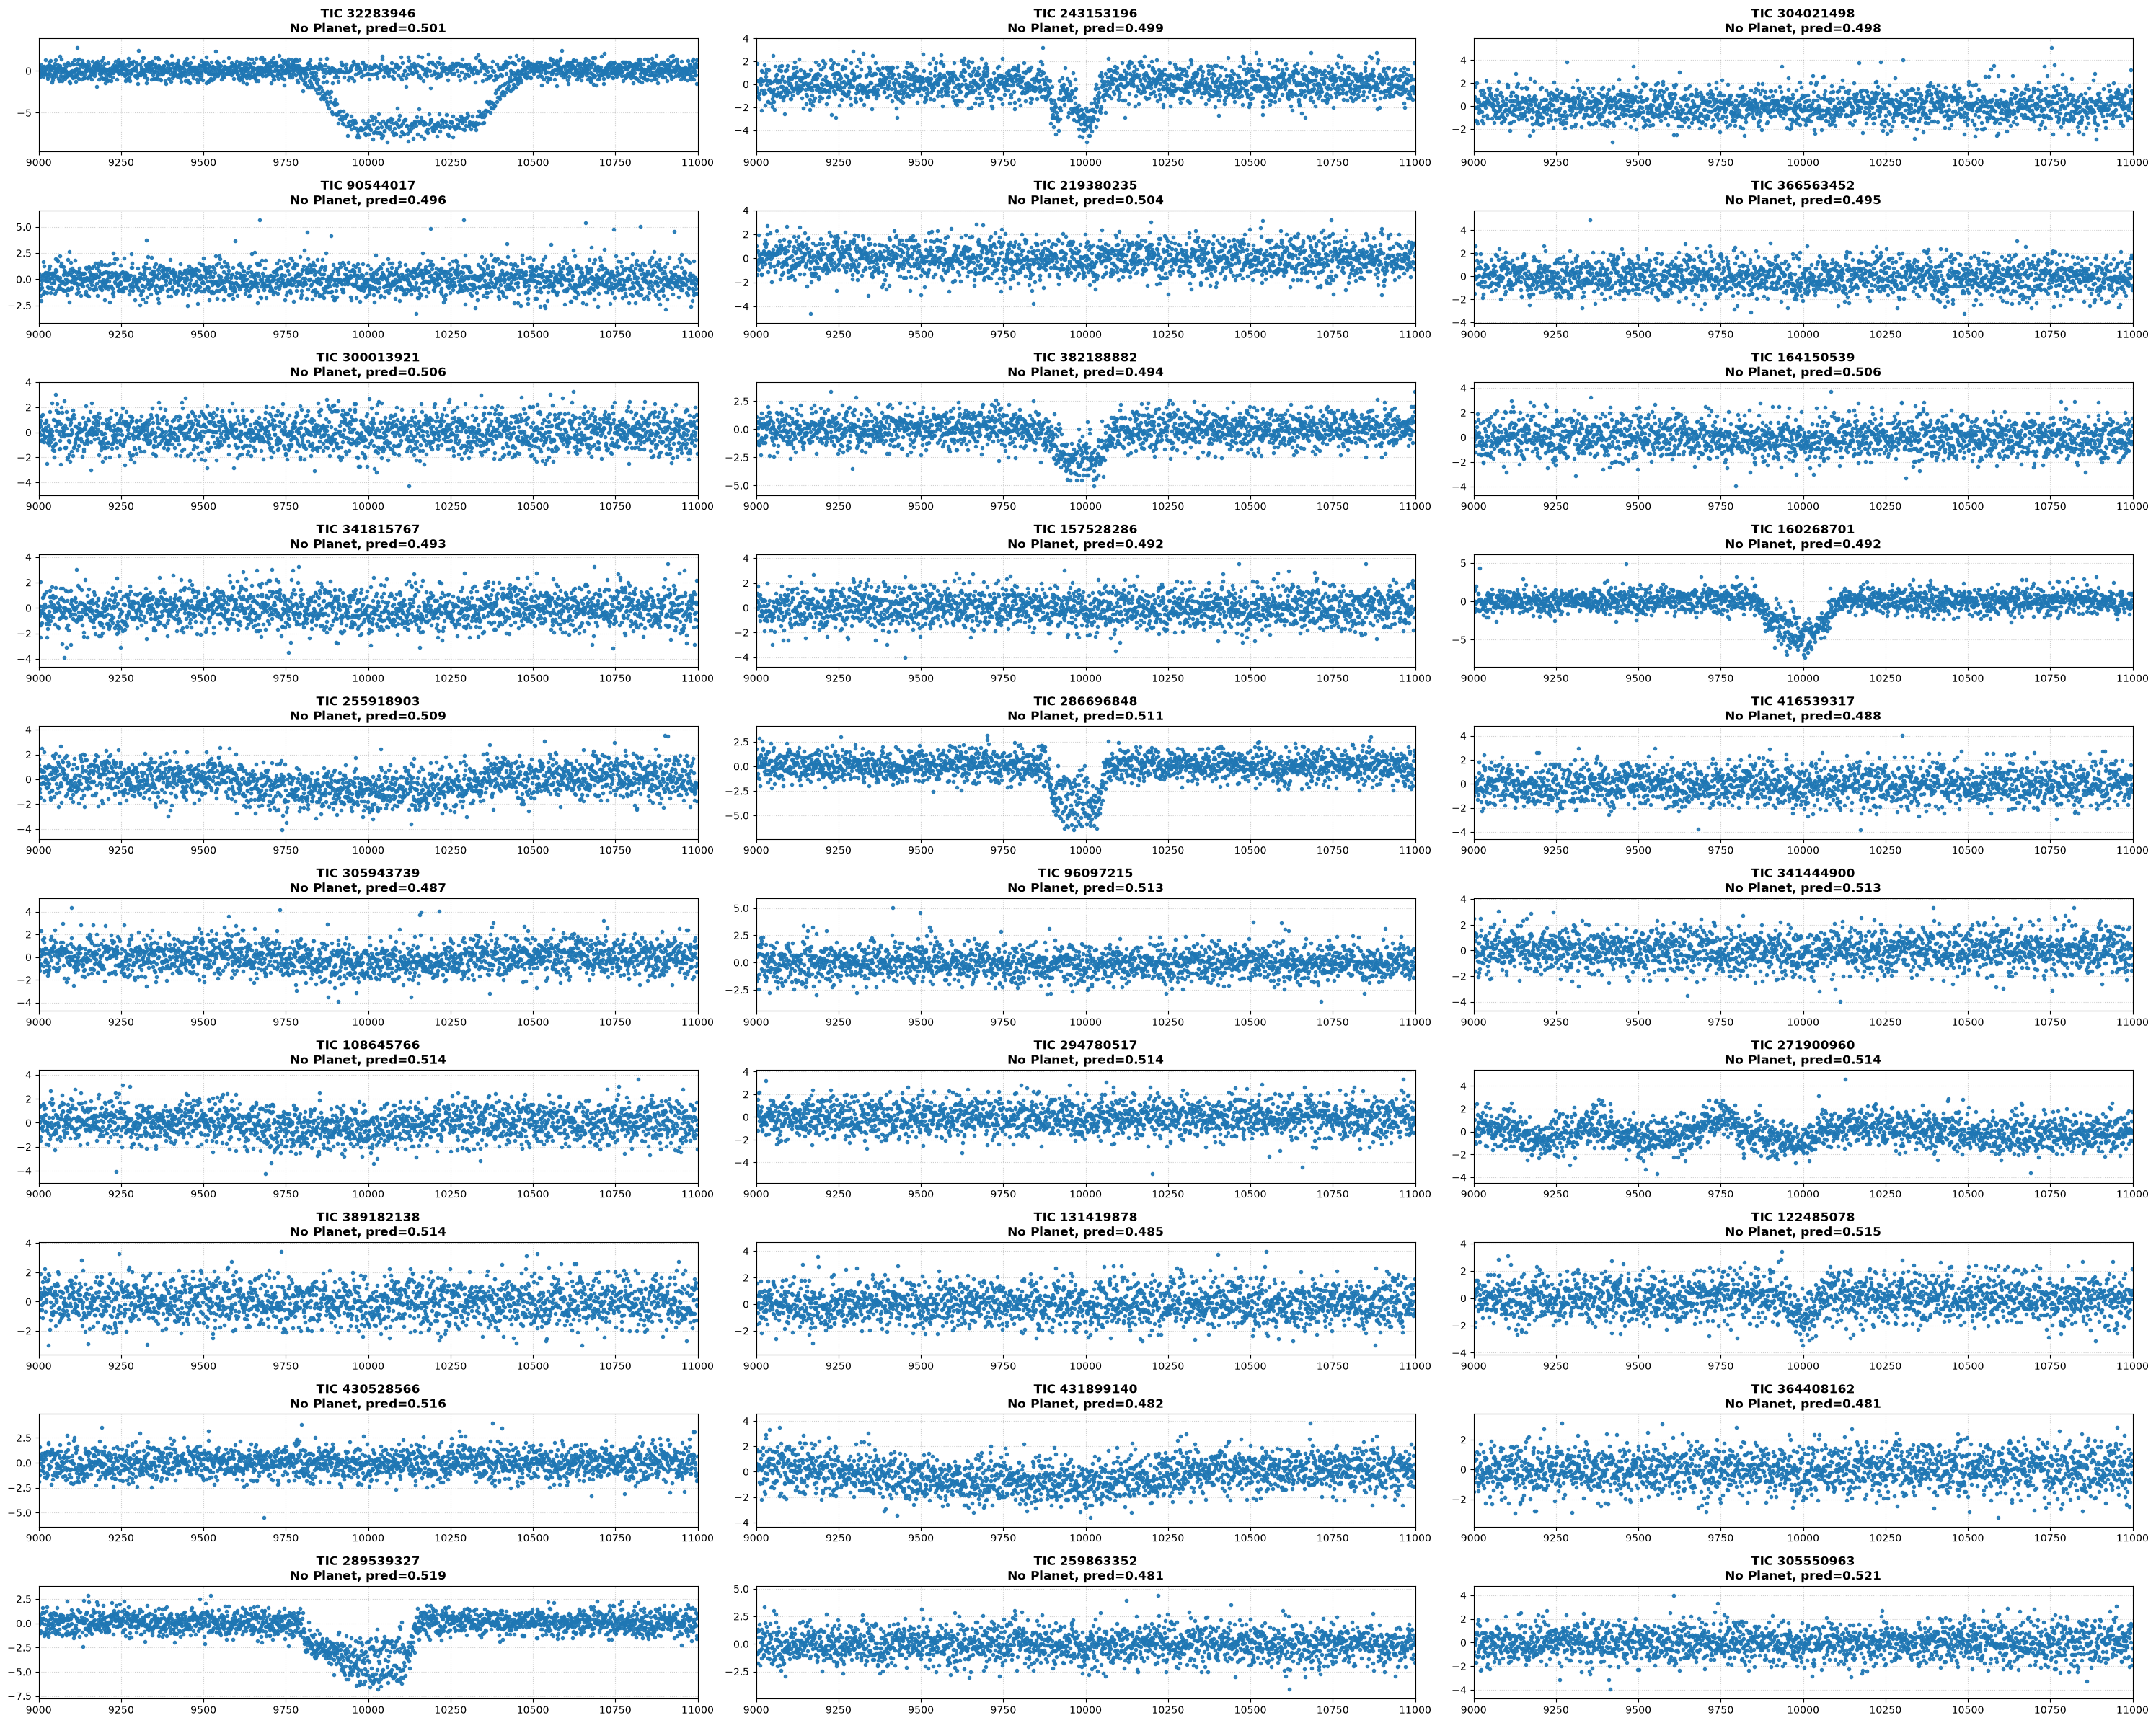

In [15]:
ambiguous_tics = no_planet.head(30)["tic_id"].tolist()

fig, axes = plt.subplots(10, 3, figsize=(30, 24))
axes = axes.flatten()

for i, tic_id in enumerate(ambiguous_tics):
    flux = np.load(Path(data_dir) / f"TIC_{tic_id}.npy").astype(np.float64)
    mean, std = flux.mean(), flux.std()
    focused = ((flux - mean) / (std + 1e-8))[9000:11000]
    x_axis = np.arange(9000, 11000)

    axes[i].plot(x_axis, focused, color='#1f77b4', alpha=0.9, linewidth=0, marker='.')
    axes[i].set_title(f"TIC {tic_id}\nNo Planet, pred={no_planet.iloc[i]['pred_prob']:.3f}", fontweight='bold')
    y_min, y_max = focused.min(), focused.max()
    pad = (y_max - y_min) * 0.1 or 0.5
    axes[i].set_ylim(y_min - pad, y_max + pad)
    axes[i].set_xlim(9000, 11000)
    axes[i].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

In [17]:
watch_tics = [382188882, 160268701, 243153196]
print(diag_df[diag_df["tic_id"].isin(watch_tics)])

#print(diag_df[diag_df["tic_id"].isin([160268701, 382188882])])

        tic_id  true_label  pred_prob
48   243153196           0   0.499106
57   160268701           0   0.491693
268  382188882           0   0.493733
